# Simulación y probabilidad · Metaheurísticas

Las metaheurísticas buscan buenas soluciones de problemas difíciles usando el azar de forma controlada: no garantizan el óptimo, pero funcionan sin gradientes y sobre cualquier representación. Este notebook construye un algoritmo genético genérico (selección por torneo, cruce, mutación y elitismo) y lo aplica a OneMax, la mochila y el viajante; implementa la búsqueda tabú y la optimización por enjambre de partículas, y termina comparando los métodos con varias semillas. El recocido simulado ya se trabaja en *Optimización · Programación lineal, entera y combinatoria*; aquí solo aparece como rival en las comparaciones.

## 1. Las piezas de un algoritmo genético

Escribir la selección por torneo (elegir $k$ individuos al azar y quedarse con el de mayor aptitud), el cruce de un punto y la mutación que invierte cada bit con probabilidad $p_m$. Comprobar que un torneo con $k$ igual al tamaño de la población elige siempre al mejor y con $k=1$ elige al azar, que cada gen del hijo viene de uno de los padres en esa posición y que la proporción de bits mutados se acerca a $p_m$.

In [1]:
import matplotlib.pyplot as plt
import numpy as np


def torneo(aptitudes, k, rng):
    candidatos = rng.integers(0, len(aptitudes), k)
    return candidatos[np.argmax(aptitudes[candidatos])]


def cruce_un_punto(p1, p2, rng):
    corte = rng.integers(1, len(p1))
    return np.concatenate([p1[:corte], p2[corte:]])


def mutar_bits(individuo, prob, rng):
    return individuo ^ (rng.random(len(individuo)) < prob)


rng = np.random.default_rng(0)
aptitudes = rng.random(20)
assert all(torneo(aptitudes, 20 * 50, rng) == aptitudes.argmax() for _ in range(100))
elegidos = np.bincount([torneo(aptitudes, 1, rng) for _ in range(20_000)], minlength=20)
print("k = 1: veces que sale cada individuo, mín", elegidos.min(), "máx", elegidos.max())
assert elegidos.min() > 800
media_k3 = np.mean([aptitudes[torneo(aptitudes, 3, rng)] for _ in range(5000)])
print(f"Aptitud media elegida: k=1 {aptitudes.mean():.3f}, k=3 {media_k3:.3f}")

padre, madre = np.zeros(12, bool), np.ones(12, bool)
hijo = cruce_un_punto(padre, madre, rng)
print("Hijo de 000…0 y 111…1:", hijo.astype(int))
assert np.all(np.diff(hijo.astype(int)) >= 0) and 0 < hijo.sum() < 12

mutado = mutar_bits(np.zeros(100_000, bool), 0.01, rng)
print(f"Proporción de bits mutados: {mutado.mean():.4f}")
assert abs(mutado.mean() - 0.01) < 0.001

k = 1: veces que sale cada individuo, mín 941 máx 1062
Aptitud media elegida: k=1 0.512, k=3 0.776
Hijo de 000…0 y 111…1: [0 0 0 0 0 0 0 1 1 1 1 1]
Proporción de bits mutados: 0.0105


## 2. OneMax

Montar un algoritmo genético genérico que reciba las funciones de aptitud, creación, cruce y mutación, conserve los `elite` mejores de cada generación y guarde la mejor aptitud y la media por generación. Usarlo para OneMax: encontrar la cadena de 100 bits con más unos. Dibujar la evolución y comprobar que llega a 100.

Mejor aptitud: 100 (alcanzada en la generación 49)


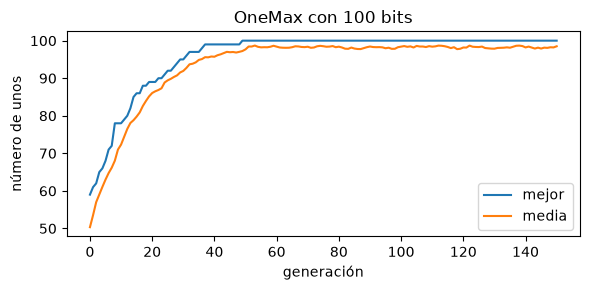

In [2]:
def algoritmo_genetico(aptitud, crear, cruzar, mutar, rng, tam=50, generaciones=100, elite=1, k=3, prob_cruce=0.9):
    poblacion = [crear(rng) for _ in range(tam)]
    apt = np.array([aptitud(x) for x in poblacion])
    historia = [(apt.max(), apt.mean())]
    for _ in range(generaciones):
        nueva = [poblacion[i] for i in np.argsort(apt)[::-1][:elite]]
        while len(nueva) < tam:
            p1, p2 = poblacion[torneo(apt, k, rng)], poblacion[torneo(apt, k, rng)]
            hijo = cruzar(p1, p2, rng) if rng.random() < prob_cruce else p1.copy()
            nueva.append(mutar(hijo, rng))
        poblacion = nueva
        apt = np.array([aptitud(x) for x in poblacion])
        historia.append((apt.max(), apt.mean()))
    mejor = int(apt.argmax())
    return poblacion[mejor], apt[mejor], np.array(historia)


L = 100
mejor, valor, historia = algoritmo_genetico(
    aptitud=lambda x: int(x.sum()),
    crear=lambda rng: rng.random(L) < 0.5,
    cruzar=cruce_un_punto,
    mutar=lambda x, rng: mutar_bits(x, 1 / L, rng),
    rng=np.random.default_rng(1), generaciones=150)
primera = int(np.argmax(historia[:, 0] == L))
print(f"Mejor aptitud: {valor} (alcanzada en la generación {primera})")
assert valor == L

plt.figure(figsize=(6, 3))
plt.plot(historia[:, 0], label="mejor")
plt.plot(historia[:, 1], label="media")
plt.xlabel("generación")
plt.ylabel("número de unos")
plt.title("OneMax con 100 bits")
plt.legend()
plt.tight_layout()
plt.show()

## 3. Elitismo y tasa de mutación

Comparar en OneMax cinco variantes: sin elitismo, con elitismo y con tres tasas de mutación (0, $1/L$ y $5/L$). Ejecutar cada una con 10 semillas durante 60 generaciones y mostrar la media y la desviación de la mejor aptitud final. Comprobar que sin mutación la población se estanca y que una mutación demasiado alta también perjudica.

In [3]:
def onemax(elite, pm, semilla, generaciones=60):
    return algoritmo_genetico(lambda x: int(x.sum()), lambda rng: rng.random(L) < 0.5, cruce_un_punto,
                              lambda x, rng: mutar_bits(x, pm, rng), np.random.default_rng(semilla),
                              generaciones=generaciones, elite=elite)[1]


variantes = {
    "sin elitismo, pm=1/L": (0, 1 / L),
    "elitismo, pm=0": (1, 0.0),
    "elitismo, pm=1/L": (1, 1 / L),
    "elitismo, pm=5/L": (1, 5 / L),
    "elitismo×5, pm=1/L": (5, 1 / L),
}
finales = {}
for nombre, (elite, pm) in variantes.items():
    finales[nombre] = np.array([onemax(elite, pm, s) for s in range(10)])
    print(f"{nombre:22} {finales[nombre].mean():6.1f} ± {finales[nombre].std():.1f}")
assert finales["elitismo, pm=1/L"].mean() > finales["elitismo, pm=0"].mean()
assert finales["elitismo, pm=1/L"].mean() > finales["elitismo, pm=5/L"].mean()

sin elitismo, pm=1/L     99.6 ± 0.5


elitismo, pm=0           80.0 ± 2.1


elitismo, pm=1/L         99.8 ± 0.4


elitismo, pm=5/L         88.3 ± 1.3


elitismo×5, pm=1/L       99.9 ± 0.3


Aquí el elitismo apenas cambia el resultado final: lo decisivo es la tasa de mutación. Sin mutación, los bits que se pierden en toda la población no pueden recuperarse; con demasiada, cada hijo estropea casi tanto como el cruce mejora.

## 4. La mochila

Una tienda de Fuerteventura tiene 40 artículos con peso y valor para un camión que aguanta un tercio del peso total. Resolverla con el algoritmo genético usando una función de reparación: si un individuo se pasa de peso, quitar los artículos con peor relación valor/peso hasta que quepa. Comparar con el óptimo exacto por programación dinámica.

In [4]:
rng_m = np.random.default_rng(4)
pesos = rng_m.integers(5, 40, 40)
valores = rng_m.integers(10, 100, 40)
capacidad = int(pesos.sum() // 3)
orden_peor = np.argsort(valores / pesos)


def reparar(x):
    x = x.copy()
    for i in orden_peor:
        if pesos[x].sum() <= capacidad:
            break
        x[i] = False
    return x


def mochila_exacta(pesos, valores, capacidad):
    mejor = np.zeros(capacidad + 1, dtype=int)
    for p, v in zip(pesos, valores):
        # el lado derecho usa la fila anterior: cada artículo entra una vez
        mejor[p:] = np.maximum(mejor[p:], mejor[:-p] + v)
    return int(mejor[capacidad])


optimo = mochila_exacta(pesos, valores, capacidad)
sol, valor_ga, historia_m = algoritmo_genetico(
    aptitud=lambda x: int(valores[x].sum()),
    crear=lambda rng: reparar(rng.random(40) < 0.3),
    cruzar=cruce_un_punto,
    mutar=lambda x, rng: reparar(mutar_bits(x, 1 / 40, rng)),
    rng=np.random.default_rng(5), tam=80, generaciones=150, elite=2)
print(f"Capacidad {capacidad}; genético: valor {valor_ga} con peso {pesos[sol].sum()}; óptimo exacto: {optimo}")
print(f"Brecha: {(optimo - valor_ga) / optimo:.2%}")
assert pesos[sol].sum() <= capacidad and valor_ga >= 0.98 * optimo

Capacidad 346; genético: valor 1248 con peso 341; óptimo exacto: 1248
Brecha: 0.00%


## 5. El viajante: cruce de orden y comprobación exacta

En el viajante el individuo es una permutación y el cruce de un punto daría ciudades repetidas. Implementar el cruce de orden (OX: copiar un tramo del primer padre y completar con las ciudades que faltan en el orden en que aparecen en el segundo) y la mutación por inversión de un tramo. Con 9 ciudades, calcular el óptimo enumerando las $8! = 40\,320$ rutas y comprobar que el genético lo encuentra.

In [5]:
from itertools import permutations


def distancias(ciudades):
    return np.linalg.norm(ciudades[:, None] - ciudades[None], axis=2)


def longitud(ruta, d):
    return d[ruta, np.roll(ruta, -1)].sum()


def cruce_orden(p1, p2, rng):
    n = len(p1)
    i, j = sorted(rng.choice(n, 2, replace=False))
    tramo = p1[i : j + 1]
    resto = [c for c in np.roll(p2, -(j + 1)) if c not in set(tramo)]
    hijo = np.empty(n, dtype=int)
    hijo[i : j + 1] = tramo
    hijo[np.roll(np.arange(n), -(j + 1))[: n - len(tramo)]] = resto
    return hijo


def mutar_inversion(ruta, prob, rng):
    if rng.random() < prob:
        i, j = sorted(rng.choice(len(ruta), 2, replace=False))
        ruta = ruta.copy()
        ruta[i : j + 1] = ruta[i : j + 1][::-1]
    return ruta


rng5 = np.random.default_rng(5)
for _ in range(200):
    hijo = cruce_orden(rng5.permutation(10), rng5.permutation(10), rng5)
    assert sorted(hijo) == list(range(10))

pequenas = rng5.uniform(0, 100, (9, 2))
d9 = distancias(pequenas)
rutas = np.array([(0, *r) for r in permutations(range(1, 9))])
longitudes = d9[rutas, np.roll(rutas, -1, axis=1)].sum(axis=1)
optima = longitudes.min()

mejor9, apt9, _ = algoritmo_genetico(lambda r: -longitud(r, d9), lambda rng: rng.permutation(9), cruce_orden,
                                     lambda r, rng: mutar_inversion(r, 0.3, rng), np.random.default_rng(6),
                                     tam=40, generaciones=60)
print(f"Rutas enumeradas: {len(rutas)}; óptimo {optima:.2f}; genético {-apt9:.2f}")
assert np.isclose(-apt9, optima)

Rutas enumeradas: 40320; óptimo 296.43; genético 296.43


## 6. El viajante con 30 ciudades

Repartir 30 pueblos al azar y resolver el viajante con el genético (población 100, 300 generaciones). Compararlo con la heurística del vecino más cercano y dibujar la mejor ruta junto a la evolución de la longitud.

Vecino más cercano: 492.7; genético: 478.3


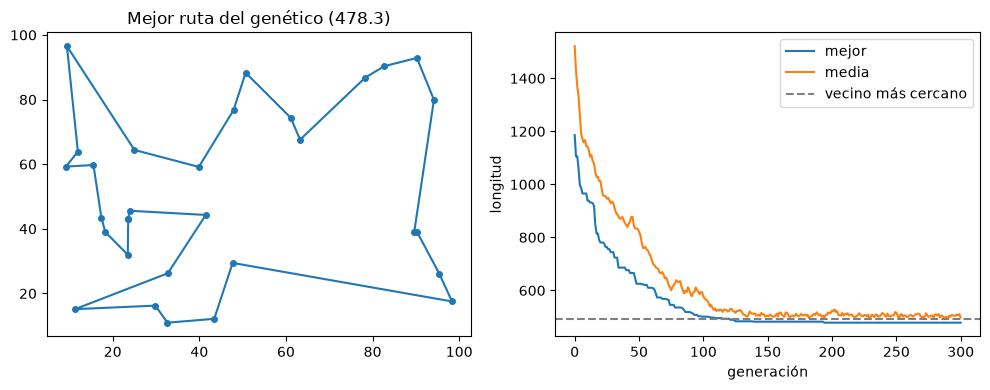

In [6]:
ciudades = np.random.default_rng(30).uniform(0, 100, (30, 2))
d = distancias(ciudades)


def vecino_mas_cercano(d, inicio=0):
    ruta, libres = [inicio], set(range(len(d))) - {inicio}
    while libres:
        siguiente = min(libres, key=lambda c: d[ruta[-1], c])
        ruta.append(siguiente)
        libres.remove(siguiente)
    return np.array(ruta)


def genetico_tsp(d, semilla, tam=100, generaciones=300):
    ruta, apt, historia = algoritmo_genetico(lambda r: -longitud(r, d), lambda rng: rng.permutation(len(d)),
                                             cruce_orden, lambda r, rng: mutar_inversion(r, 0.3, rng),
                                             np.random.default_rng(semilla), tam=tam, generaciones=generaciones,
                                             elite=2)
    return ruta, -apt, -historia


ruta_vc = vecino_mas_cercano(d)
ruta_ga, long_ga, historia_ga = genetico_tsp(d, 0)
print(f"Vecino más cercano: {longitud(ruta_vc, d):.1f}; genético: {long_ga:.1f}")
assert long_ga < longitud(ruta_vc, d)

fig, ejes = plt.subplots(1, 2, figsize=(10, 4))
cerrada = np.append(ruta_ga, ruta_ga[0])
ejes[0].plot(*ciudades[cerrada].T, "-o", ms=4)
ejes[0].set_title(f"Mejor ruta del genético ({long_ga:.1f})")
ejes[1].plot(historia_ga[:, 0], label="mejor")
ejes[1].plot(historia_ga[:, 1], label="media")
ejes[1].axhline(longitud(ruta_vc, d), color="gray", ls="--", label="vecino más cercano")
ejes[1].set_xlabel("generación")
ejes[1].set_ylabel("longitud")
ejes[1].legend()
plt.tight_layout()
plt.show()

## 7. Búsqueda tabú

La búsqueda local con movimientos 2-opt (invertir un tramo de la ruta) se detiene en el primer óptimo local. La búsqueda tabú sigue avanzando: en cada paso toma el mejor vecino aunque empeore, y para no volver atrás prohíbe durante unas iteraciones volver a añadir las aristas que acaba de quitar, salvo que el movimiento mejore la mejor ruta conocida (criterio de aspiración). Comparar las dos desde las mismas rutas iniciales aleatorias.

inicio  búsqueda local    tabú
     0           459.3   459.3
     1           494.3   468.7
     2           486.6   456.6
     3           483.7   468.7
     4           477.6   456.6


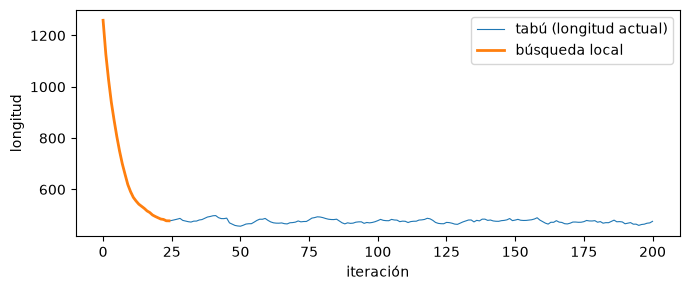

In [7]:
def movimientos_2opt(n):
    I, J = np.triu_indices(n, 2)
    valido = ~((I == 0) & (J == n - 1))
    return I[valido], J[valido]


def busqueda_tabu(d, ruta, iteraciones, permanencia=10, tabu=True):
    n = len(ruta)
    I, J = movimientos_2opt(n)
    ruta = ruta.copy()
    actual = mejor_long = longitud(ruta, d)
    mejor_ruta, prohibida_hasta, historia = ruta.copy(), np.zeros((n, n)), [actual]
    for it in range(1, iteraciones + 1):
        a, b, c, e = ruta[I], ruta[I + 1], ruta[J], ruta[(J + 1) % n]
        delta = d[a, c] + d[b, e] - d[a, b] - d[c, e]
        if not tabu and delta.min() >= -1e-9:
            break
        prohibido = (prohibida_hasta[a, c] > it) | (prohibida_hasta[b, e] > it)
        permitido = ~prohibido | (actual + delta < mejor_long - 1e-9)
        k = np.argmin(np.where(permitido, delta, np.inf))
        i, j = I[k], J[k]
        for x, y in [(a[k], b[k]), (c[k], e[k])]:
            prohibida_hasta[x, y] = prohibida_hasta[y, x] = it + permanencia
        ruta[i + 1 : j + 1] = ruta[i + 1 : j + 1][::-1]
        actual += delta[k]
        if actual < mejor_long - 1e-9:
            mejor_long, mejor_ruta = actual, ruta.copy()
        historia.append(actual)
    assert np.isclose(longitud(mejor_ruta, d), mejor_long)
    return mejor_ruta, mejor_long, historia


print(f"{'inicio':>6}{'búsqueda local':>16}{'tabú':>8}")
for semilla in range(5):
    inicio = np.random.default_rng(semilla).permutation(30)
    _, local, hist_local = busqueda_tabu(d, inicio, 1000, tabu=False)
    _, mejor_tabu, hist_tabu = busqueda_tabu(d, inicio, 200)
    print(f"{semilla:6}{local:16.1f}{mejor_tabu:8.1f}")
    assert mejor_tabu <= local + 1e-9

plt.figure(figsize=(7, 3))
plt.plot(hist_tabu, lw=0.8, label="tabú (longitud actual)")
plt.plot(hist_local, lw=2, label="búsqueda local")
plt.xlabel("iteración")
plt.ylabel("longitud")
plt.legend()
plt.tight_layout()
plt.show()

La curva de la búsqueda tabú no es monótona: tras llegar al óptimo local acepta movimientos que empeoran y, al no poder deshacerlos, explora otra zona del espacio, donde a veces encuentra una ruta mejor.

## 8. Enjambre de partículas

Implementar la optimización por enjambre de partículas (PSO): cada partícula tiene posición y velocidad, y en cada paso
$v \leftarrow w\,v + c_1 r_1 (p_{\text{mejor}} - x) + c_2 r_2 (g_{\text{mejor}} - x)$, $x \leftarrow x + v$, con $r_1, r_2$ uniformes. Minimizar la función de Rastrigin en 2D, que tiene un mínimo global 0 en el origen rodeado de muchos mínimos locales, y dibujar el enjambre en tres momentos.

Mejor punto: [0. 0.], valor 0.00e+00


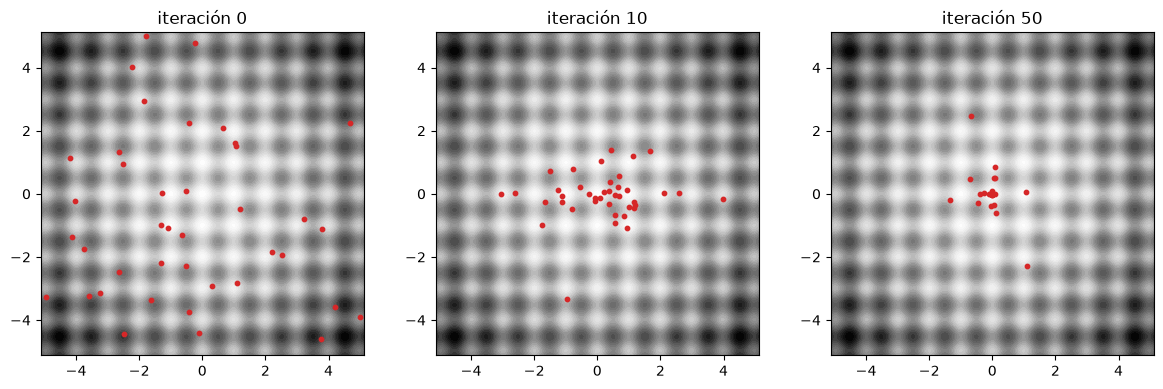

In [8]:
def rastrigin(X):
    X = np.asarray(X)
    return 10 * X.shape[-1] + np.sum(X**2 - 10 * np.cos(2 * np.pi * X), axis=-1)


def pso(f, dim, limite, rng, particulas=40, iteraciones=200, w=0.72, c1=1.49, c2=1.49, guardar=()):
    x = rng.uniform(-limite, limite, (particulas, dim))
    v = np.zeros_like(x)
    p_mejor, p_valor = x.copy(), f(x)
    g = p_mejor[p_valor.argmin()].copy()
    historia, fotos = [p_valor.min()], {0: x.copy()}
    for it in range(1, iteraciones + 1):
        r1, r2 = rng.random(x.shape), rng.random(x.shape)
        v = w * v + c1 * r1 * (p_mejor - x) + c2 * r2 * (g - x)
        x = np.clip(x + v, -limite, limite)
        valor = f(x)
        mejora = valor < p_valor
        p_mejor[mejora], p_valor[mejora] = x[mejora], valor[mejora]
        g = p_mejor[p_valor.argmin()].copy()
        historia.append(p_valor.min())
        if it in guardar:
            fotos[it] = x.copy()
    return g, p_valor.min(), np.array(historia), fotos


g, valor_pso, historia_pso, fotos = pso(rastrigin, 2, 5.12, np.random.default_rng(8), guardar=(10, 50))
print(f"Mejor punto: {g.round(5)}, valor {valor_pso:.2e}")
assert rastrigin(np.zeros(2)) == 0 and valor_pso < 1e-6

malla = np.linspace(-5.12, 5.12, 300)
MX, MY = np.meshgrid(malla, malla)
Zr = rastrigin(np.stack([MX, MY], axis=-1))
fig, ejes = plt.subplots(1, 3, figsize=(12, 3.8))
for eje, (it, posiciones) in zip(ejes, fotos.items()):
    eje.contourf(MX, MY, Zr, levels=30, cmap="Greys")
    eje.scatter(*posiciones.T, c="tab:red", s=10)
    eje.set_title(f"iteración {it}")
    eje.set_aspect("equal")
plt.tight_layout()
plt.show()

## 9. La inercia del enjambre

El peso de inercia $w$ equilibra exploración y explotación. Minimizar Rastrigin en 10 dimensiones con $w \in \{0{,}3;\ 0{,}5;\ 0{,}72;\ 0{,}9\}$ (manteniendo $c_1 = c_2 = 1{,}49$) y 10 semillas por valor, y mostrar la media y la desviación del mejor valor final. Con $w$ cercano a 1 las velocidades apenas se frenan y el enjambre no converge.

In [9]:
resultados_w = {}
print(f"{'w':>5}{'media':>9}{'desv.':>8}")
for w in (0.3, 0.5, 0.72, 0.9):
    resultados_w[w] = np.array([pso(rastrigin, 10, 5.12, np.random.default_rng(s), iteraciones=300, w=w)[1]
                                for s in range(10)])
    print(f"{w:5}{resultados_w[w].mean():9.2f}{resultados_w[w].std():8.2f}")
assert resultados_w[0.72].mean() < resultados_w[0.9].mean()

    w    media   desv.
  0.3    14.43    3.86
  0.5    14.82    9.95


 0.72     6.97    3.18
  0.9    44.51    9.38


## 10. Comparar en el viajante con varias semillas

Con las 30 ciudades del ejercicio 6, ejecutar 10 semillas de tres métodos con un presupuesto parecido de unas 30 000 rutas evaluadas: el genético (población 100, 300 generaciones), la búsqueda tabú (unas 75 iteraciones de ~400 vecinos) y un recocido simulado con movimientos 2-opt. Mostrar la media, la desviación y el mejor resultado de cada uno, y la brecha media respecto a la mejor ruta encontrada por cualquiera.

In [10]:
def recocido(d, rng, iteraciones=30_000, t0=50.0, t_fin=0.05):
    n = len(d)
    ruta = rng.permutation(n)
    actual = mejor = longitud(ruta, d)
    enfriamiento = (t_fin / t0) ** (1 / iteraciones)
    t = t0
    for _ in range(iteraciones):
        i, j = sorted(rng.choice(n, 2, replace=False))
        if j - i < 2 or (i == 0 and j == n - 1):
            continue
        a, b, c, e = ruta[i], ruta[i + 1], ruta[j], ruta[(j + 1) % n]
        delta = d[a, c] + d[b, e] - d[a, b] - d[c, e]
        if delta < 0 or rng.random() < np.exp(-delta / t):
            ruta[i + 1 : j + 1] = ruta[i + 1 : j + 1][::-1]
            actual += delta
            mejor = min(mejor, actual)
        t *= enfriamiento
    return mejor


vecinos = len(movimientos_2opt(30)[0])
comparacion = {"genético": [], "tabú": [], "recocido": []}
for s in range(10):
    comparacion["genético"].append(genetico_tsp(d, s)[1])
    comparacion["tabú"].append(busqueda_tabu(d, np.random.default_rng(s).permutation(30), 30_000 // vecinos)[1])
    comparacion["recocido"].append(recocido(d, np.random.default_rng(s)))
mejor_conocida = min(min(v) for v in comparacion.values())

print(f"{'método':10}{'media':>8}{'desv.':>7}{'mejor':>8}{'brecha media':>14}")
for nombre, valores_m in comparacion.items():
    v = np.array(valores_m)
    print(f"{nombre:10}{v.mean():8.1f}{v.std():7.1f}{v.min():8.1f}{(v.mean() / mejor_conocida - 1):14.1%}")
print(f"Vecino más cercano: {longitud(ruta_vc, d):.1f}")
assert all(np.mean(v) < longitud(ruta_vc, d) for v in comparacion.values())

método       media  desv.   mejor  brecha media
genético     475.1   14.0   456.6          4.0%
tabú         462.2    6.1   456.6          1.2%
recocido     463.7    7.6   456.6          1.5%
Vecino más cercano: 492.7


El genético trabaja «a ciegas» con la permutación, mientras que la búsqueda tabú y el recocido usan movimientos 2-opt, que aprovechan la geometría del problema (quitar cruces). Por eso, con el mismo presupuesto, los métodos de trayectoria suelen ganar en el viajante; un genético competitivo añadiría búsqueda local a cada hijo (algoritmo memético).

## 11. Comparar en una función continua

Minimizar Rastrigin en 5 dimensiones con 10 semillas y unas 10 000 evaluaciones por ejecución con cuatro métodos: búsqueda aleatoria, el genético con genes reales (cruce BLX-α y mutación gaussiana), PSO y `scipy.optimize.differential_evolution`. Mostrar la media y la desviación del mejor valor y dibujarlas en un diagrama de cajas.

método                   media   desv.    mejor
aleatoria                15.51    2.51 1.26e+01
genético                  0.74    0.75 5.27e-04
PSO                       1.19    1.39 5.12e-13
evolución diferencial     0.50    0.80 0.00e+00


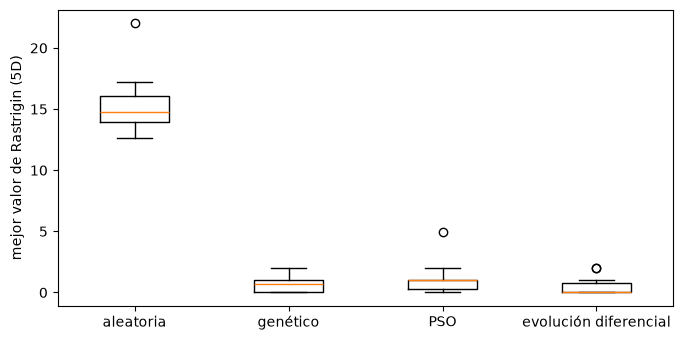

In [11]:
from scipy.optimize import differential_evolution

dim, limite = 5, 5.12


def cruce_blx(p1, p2, rng, alfa=0.3):
    bajo, alto = np.minimum(p1, p2), np.maximum(p1, p2)
    margen = alfa * (alto - bajo)
    return np.clip(rng.uniform(bajo - margen, alto + margen), -limite, limite)


def mutar_gauss(x, rng, prob=0.2, sigma=0.3):
    mascara = rng.random(len(x)) < prob
    return np.clip(x + mascara * rng.normal(0, sigma, len(x)), -limite, limite)


def metodos(semilla):
    rng = np.random.default_rng(semilla)
    aleatoria = rastrigin(rng.uniform(-limite, limite, (10_000, dim))).min()
    genetico = -algoritmo_genetico(lambda x: -rastrigin(x), lambda r: r.uniform(-limite, limite, dim), cruce_blx,
                                   mutar_gauss, rng, tam=50, generaciones=200, elite=2)[1]
    enjambre = pso(rastrigin, dim, limite, rng, particulas=40, iteraciones=250)[1]
    de = differential_evolution(lambda x: rastrigin(x), [(-limite, limite)] * dim, popsize=10, maxiter=200,
                                tol=0, polish=False, rng=semilla)
    return {"aleatoria": aleatoria, "genético": genetico, "PSO": enjambre, "evolución diferencial": de.fun}


filas = [metodos(s) for s in range(10)]
continua = {nombre: np.array([f[nombre] for f in filas]) for nombre in filas[0]}
print(f"{'método':22}{'media':>8}{'desv.':>8}{'mejor':>9}")
for nombre, v in continua.items():
    print(f"{nombre:22}{v.mean():8.2f}{v.std():8.2f}{v.min():9.2e}")
assert all(continua[m].mean() < continua["aleatoria"].mean() for m in ("genético", "PSO", "evolución diferencial"))

plt.figure(figsize=(7, 3.5))
plt.boxplot(list(continua.values()), tick_labels=list(continua))
plt.ylabel("mejor valor de Rastrigin (5D)")
plt.tight_layout()
plt.show()

Ninguna metaheurística es la mejor en todo (*no free lunch*): el resultado depende del problema, de la representación y del ajuste de los parámetros. Por eso se comparan siempre con varias semillas y con el mismo presupuesto, y se informa de la dispersión además de la media.